## Differential equations

`ode45` solves $y' = f(t, y)$ from an initial value with an adaptive Runge-Kutta method: it takes small steps where the solution changes fast and long ones where it doesn't. A system of higher order becomes a first-order one by naming the derivatives.

### A damped pendulum

$\theta'' = -\frac{g}{L}\sin\theta - c\,\theta'$, written as the system $y_1 = \theta$, $y_2 = \theta'$. It starts nearly upside down and swings down to rest.

final angle 0.2620 rad


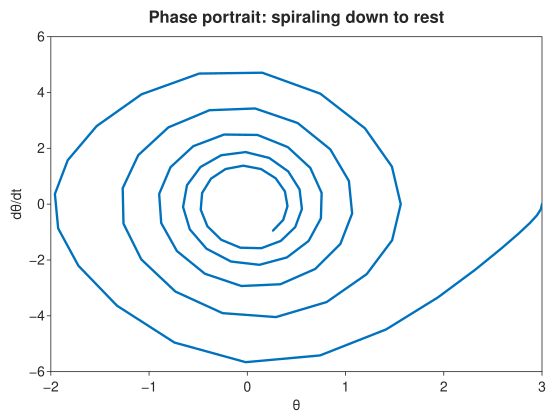

In [ ]:
figure
g = 9.81; L = 1; damping = 0.3;
pendulum = @(t, y) [y(2); -g/L*sin(y(1)) - damping*y(2)];
[tp, yp] = ode45(pendulum, linspace(0, 12, 90), [3; 0]);
plot(yp(:, 1), yp(:, 2), 'LineWidth', 1.2)
xlabel('\theta'), ylabel('d\theta/dt'), title('Phase portrait: spiraling down to rest')
fprintf('final angle %.4f rad\n', yp(end, 1))

### The Lorenz attractor

$x' = \sigma(y - x)$, $y' = x(\rho - z) - y$, $z' = xy - \beta z$, with Lorenz's $\sigma = 10$, $\rho = 28$, $\beta = 8/3$. The solution never settles and never repeats, yet stays on a butterfly-shaped set; nearby starting points separate exponentially fast.

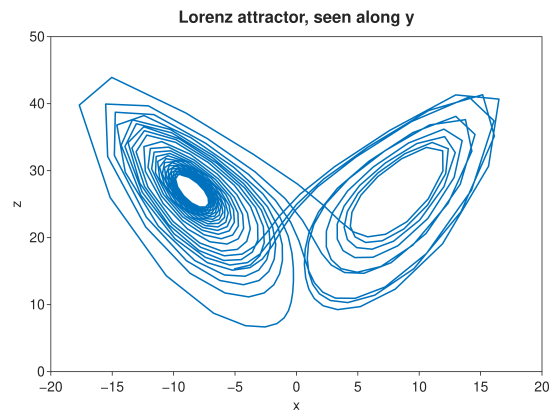

In [ ]:
figure
sigma = 10; rho = 28; beta = 8/3;
lorenz = @(t, u) [sigma*(u(2) - u(1)); u(1)*(rho - u(3)) - u(2); u(1)*u(2) - beta*u(3)];
[tl, ul] = ode45(lorenz, linspace(0, 25, 500), [1; 1; 1]);
keep = tl > 1;
plot(ul(keep, 1), ul(keep, 3), 'LineWidth', 0.6)
xlabel('x'), ylabel('z')
title('Lorenz attractor, seen along y')

### Sensitive dependence

Start a second solution $10^{-6}$ away and print the distance between the two. It stays small for a while, then grows about tenfold every two or three time units. (The tolerances are tighter than the default, so the solver's own error stays far below $10^{-6}$.)

In [ ]:
opts = odeset('RelTol', 1e-8, 'AbsTol', 1e-10);
times = linspace(0, 25, 251);
[~, ua] = ode45(lorenz, times, [1; 1; 1], opts);
[~, ub] = ode45(lorenz, times, [1 + 1e-6; 1; 1], opts);
gap = sqrt(sum((ua - ub).^2, 2));
for T = [5 10 15 20 25]
    fprintf('t = %2d: distance %.1e\n', T, gap(find(times >= T, 1)))
end

t =  5: distance 1.2e-06


t = 10: distance 1.8e-06
t = 15: distance 2.4e-05
t = 20: distance 9.3e-04
t = 25: distance 1.4e-01


### The van der Pol oscillator

$x'' - \mu(1 - x^2)x' + x = 0$ pumps energy in at small amplitude and damps it at large amplitude, so every solution but the rest point is drawn to one closed orbit, a limit cycle. Two starts, one inside and one outside, end on the same cycle.

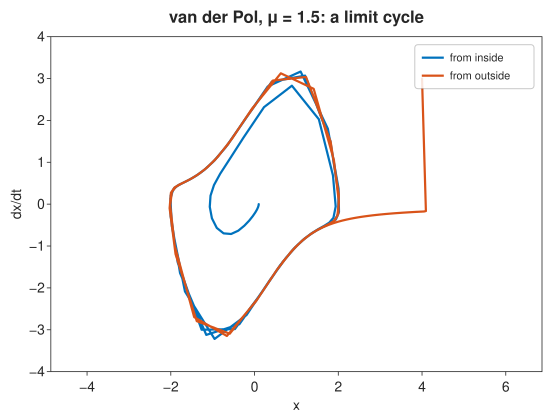

In [ ]:
figure
mu = 1.5;
vdp = @(t, y) [y(2); mu*(1 - y(1)^2)*y(2) - y(1)];
[~, yin] = ode45(vdp, linspace(0, 25, 100), [0.1; 0]);
[~, yout] = ode45(vdp, linspace(0, 25, 100), [4; 3]);
plot(yin(:, 1), yin(:, 2), yout(:, 1), yout(:, 2), 'LineWidth', 1.1)
legend('from inside', 'from outside')
xlabel('x'), ylabel('dx/dt'), title(sprintf('van der Pol, \\mu = %g: a limit cycle', mu))
axis equal

*Topics after examples in MatRust-Studio (MIT license); the code here is Sagebrush's own.*